<a href="https://colab.research.google.com/github/ali-yyyy/Deep-Learning-Lab/blob/main/DL_Lab6_232411_Ali_Asghar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Ali Asghar
#232411
#Deep Learning Lab 6

Import and Load CIFAR-10


In [1]:
!pip install -U datasets huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 54.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 18.9 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0

Train images: (50000, 32, 32, 3)
Train labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)
Raw pixel range: 0 to 255


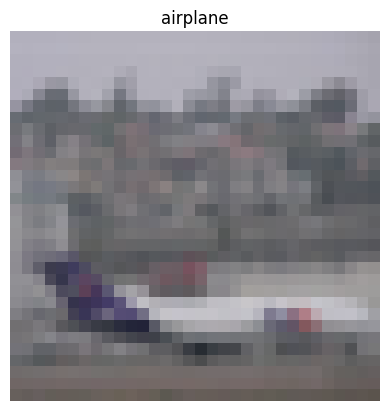

In [9]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
from datasets import load_dataset

tf.keras.utils.set_random_seed(42)

# Stream CIFAR-10 train and test splits from Hugging Face
train_dataset = load_dataset(
    "uoft-cs/cifar10",
    split="train",
    streaming=True
)

test_dataset = load_dataset(
    "uoft-cs/cifar10",
    split="test",
    streaming=True
)

# Load samples
train_samples = list(train_dataset.take(100000))
test_samples = list(test_dataset.take(100000))

# Convert train images and labels
x_train = np.array([
    np.array(sample["img"].convert("RGB"))
    for sample in train_samples
])
y_train = np.array([
    sample["label"] for sample in train_samples
])

# Convert test images and labels
x_test = np.array([
    np.array(sample["img"].convert("RGB"))
    for sample in test_samples
])
y_test = np.array([
    sample["label"] for sample in test_samples
])

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Train images:", x_train.shape)
print("Train labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)
print("Raw pixel range:", x_train.min(), "to", x_train.max())

# Preserve the original image for OpenCV filters
sample_uint8 = x_train[0].copy()

# Normalize pixels to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Display an image and its label
plt.imshow(sample_uint8)
plt.title(class_names[int(y_train[0])])
plt.axis("off")
plt.show()

Apply All Fixed Filters

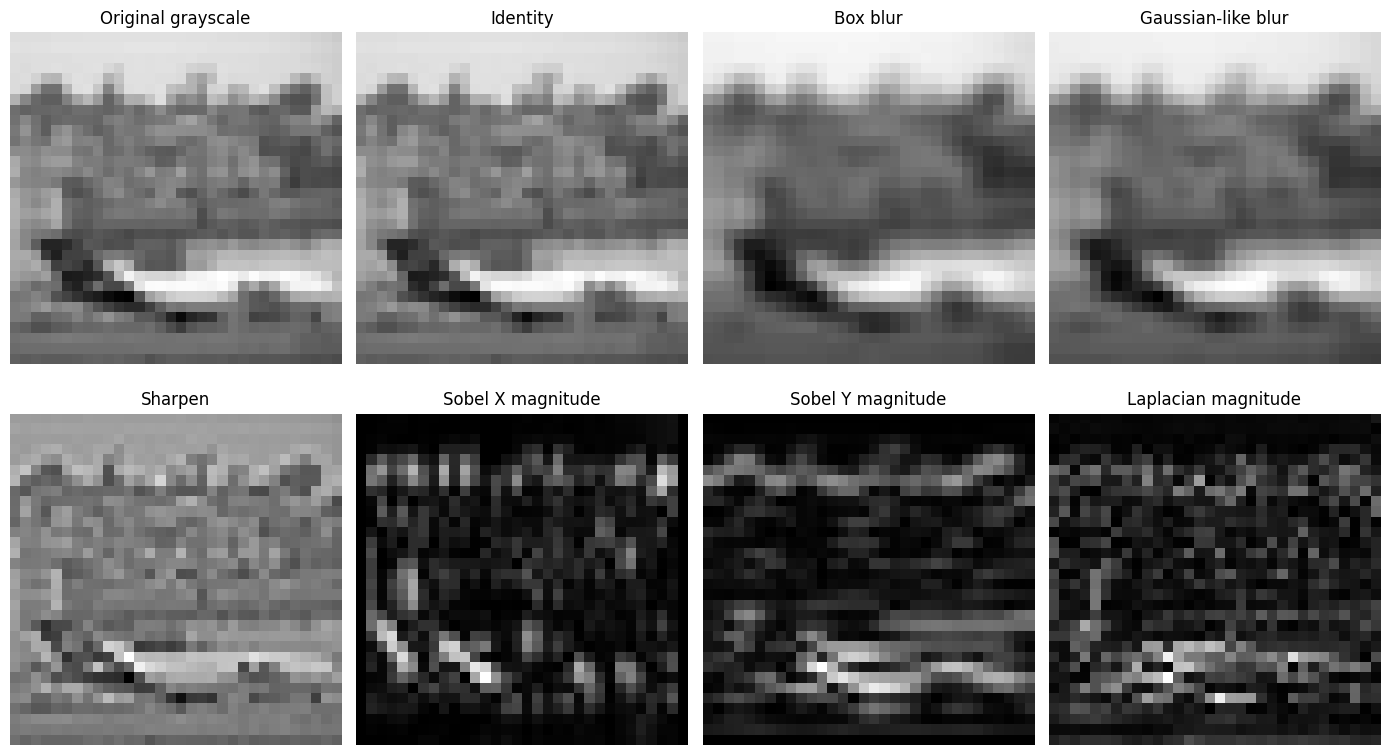

In [3]:
# Convert the sample RGB image to grayscale for easier filter comparison.
gray = cv2.cvtColor(sample_uint8, cv2.COLOR_RGB2GRAY)

# 1. Identity kernel: center value is 1, other values are 0.
identity_kernel = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0]
], dtype=np.float32)
identity = cv2.filter2D(gray, -1, identity_kernel)

# 2. Box blur: averages a 3x3 neighborhood.
box_kernel = np.ones((3, 3), dtype=np.float32) / 9.0
box_blur = cv2.filter2D(gray, -1, box_kernel)

# 3. Gaussian-like blur: center pixels receive larger weights.
gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16.0
gaussian_blur = cv2.filter2D(gray, -1, gaussian_kernel)

# 4. Sharpen: enhances local contrast and edges.
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)
sharpen = cv2.filter2D(gray, cv2.CV_32F, sharpen_kernel)

# 5. Sobel X: estimates intensity changes in the x direction.
sobel_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)

# 6. Sobel Y: estimates intensity changes in the y direction.
sobel_y = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

# 7. Laplacian: responds to rapid intensity changes in several directions.
laplacian = cv2.Laplacian(gray, cv2.CV_32F, ksize=3)

# Prepare outputs. Absolute values help display negative edge responses.
results = [
    (gray, "Original grayscale", "gray"),
    (identity, "Identity", "gray"),
    (box_blur, "Box blur", "gray"),
    (gaussian_blur, "Gaussian-like blur", "gray"),
    (sharpen, "Sharpen", "gray"),
    (np.abs(sobel_x), "Sobel X magnitude", "gray"),
    (np.abs(sobel_y), "Sobel Y magnitude", "gray"),
    (np.abs(laplacian), "Laplacian magnitude", "gray")
]

# Plot original and all seven filter outputs.
plt.figure(figsize=(14, 8))
for i, (image, title, cmap) in enumerate(results):
    plt.subplot(2, 4, i + 1)
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Task 2: Apply and Analyze Fixed Filters

6. **Visible effects of filters:**
   - **Blurring:** Smoothes high-frequency noise using local neighborhood averaging (Gaussian-like preserves central geometry better than Box).
   - **Sharpening:** Enhances high-frequency edges by boosting difference contrast between neighboring pixels.
   - **Edge Filters:** Isolate boundary transitions (Sobel calculates directional first-order gradients; Laplacian calculates multi-directional second-order derivatives).
   - **Sobel X vs. Sobel Y:** Sobel X extracts vertical edge boundaries, while Sobel Y extracts horizontal edge boundaries.

Numerical kernel demonstration in code

In [4]:
# The same 4x4 image matrix used in the manual.
X = np.array([
    [1, 2, 3, 0],
    [4, 5, 6, 1],
    [7, 8, 9, 2],
    [0, 1, 2, 3]
], dtype=np.float32)

# 3x3 averaging kernel.
K = np.ones((3, 3), dtype=np.float32) / 9.0

# Calculate the valid 2x2 output explicitly, without an image library.
output = np.zeros((2, 2), dtype=np.float32)
for i in range(2):
    for j in range(2):
        patch = X[i : i + 3, j : j + 3]  # Select one 3x3 patch.
        output[i, j] = np.sum(patch * K)  # Multiply and sum.

print("Input matrix:\n", X)
print("Averaging kernel:\n", K)
print("Output matrix:\n", np.round(output, 2))

Input matrix:
 [[1. 2. 3. 0.]
 [4. 5. 6. 1.]
 [7. 8. 9. 2.]
 [0. 1. 2. 3.]]
Averaging kernel:
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
Output matrix:
 [[5.   4.  ]
 [4.67 4.11]]


### Task 1: Numerical Convolution & Filter Theory

1. **Element-wise multiplication and sum (top-left output):**
   - Element-wise product sum is $1(1) + 2(1) + 3(1) + 4(1) + 5(1) + 6(1) + 7(1) + 8(1) + 9(1) = 45$, which when scaled by $1/9$ equals $5.0$.

2. **Final 2x2 output matrix:**
   - $\text{Output} = \begin{bmatrix} 5.00 & 4.00 \\ 4.67 & 4.11 \end{bmatrix}$

3. **Core terminology definitions:**
   - **Kernel:** A small matrix of weights used to slide across input data to extract local patterns.
   - **Stride:** The step size (number of pixels) the kernel shifts during convolution.
   - **Padding:** Adding zero border pixels around the input to control output spatial dimensions.
   - **Feature Map:** The matrix of activation values containing detected features from a layer.
   - **Fixed vs. Learned Filters:** Fixed filters have static hand-coded weights, while learned filters adaptively update weights via gradient descent.

Train a Simple CNN

In [8]:
# A compact CNN suitable for 32x32 CIFAR-10 images.
simple_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    # Learn 32 local patterns using 3x3 filters.
    tf.keras.layers.Conv2D(
        32, 3, padding="same", activation="relu", name="simple_conv1"
    ),
    tf.keras.layers.MaxPooling2D(),

    # Learn 64 more complex patterns.
    tf.keras.layers.Conv2D(
        64, 3, padding="same", activation="relu", name="simple_conv2"
    ),
    tf.keras.layers.MaxPooling2D(),

    # Learn 128-channel features at a smaller spatial size.
    tf.keras.layers.Conv2D(
        128, 3, padding="same", activation="relu", name="simple_conv3"
    ),

    # Average each feature map into one number.
    tf.keras.layers.GlobalAveragePooling2D(),

    # Output ten class probabilities.
    tf.keras.layers.Dense(10, activation="softmax")
])

# Configure training.
simple_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Inspect the model before training.
simple_cnn.summary()

# Train for five epochs for a practical classroom baseline.
simple_history = simple_cnn.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Evaluate once on the held-out test set.
simple_loss, simple_acc = simple_cnn.evaluate(x_test, y_test, verbose=1)
print("Simple CNN test loss:", simple_loss)
print("Simple CNN test accuracy:", simple_acc)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_conv1 (Conv2D)           │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_conv2 (Conv2D)           │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_conv3 (Conv2D)           │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,538 (369.29 KB)

 Trainable params: 94,538 (369.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.3052 - loss: 1.8614 - val_accuracy: 0.3732 - val_loss: 1.7089
Epoch 2/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.4070 - loss: 1.6147 - val_accuracy: 0.4400 - val_loss: 1.5487
Epoch 3/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.4592 - loss: 1.4946 - val_accuracy: 0.4852 - val_loss: 1.4345
Epoch 4/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4918 - loss: 1.4087 - val_accuracy: 0.5104 - val_loss: 1.3673
Epoch 5/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5175 - loss: 1.3449 - val_accuracy: 0.5302 - val_loss: 1.3183
Epoch 6/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5386 - loss: 1.2916 - val_accuracy: 0.5412 - val_loss: 1.2760
Epoch 7/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5576 - loss: 1.2438 - val_accuracy: 0.5548 - val_loss: 1.2394
Epoch 8/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5738 - loss: 1.2022 - val_accuracy: 0

Inspect Learned Filters and Feature Maps

12.1 Plot the first-layer learned kernels

Kernel shape: (3, 3, 3, 32)
Bias shape: (32,)


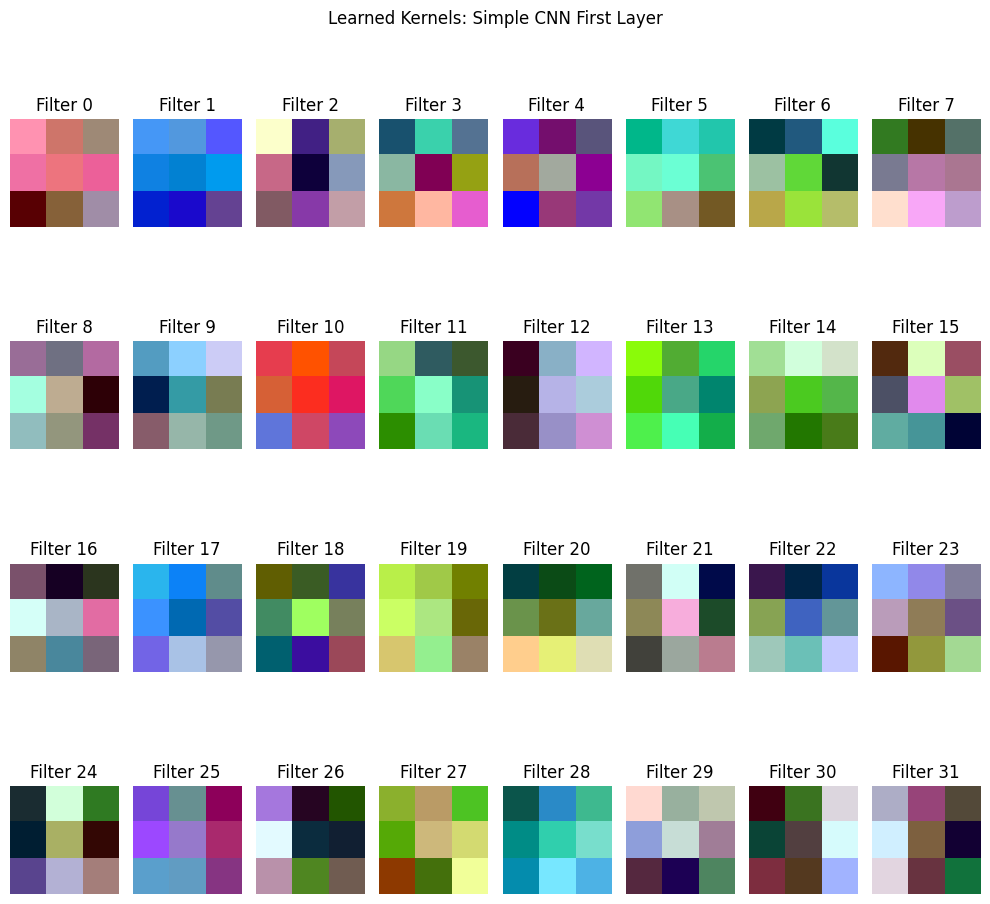

In [10]:
# Get the first convolutional layer from the trained simple CNN.
first_layer = simple_cnn.get_layer("simple_conv1")

# Kernel shape: (kernel_height, kernel_width, input_channels, number_of_filters).
kernels, biases = first_layer.get_weights()
print("Kernel shape:", kernels.shape)
print("Bias shape:", biases.shape)

# Plot up to 32 learned RGB kernels.
plt.figure(figsize=(10, 10))
for i in range(min(32, kernels.shape[-1])):
    kernel = kernels[:, :, :, i]
    # Scale each kernel only for display; model weights are not modified.
    low, high = kernel.min(), kernel.max()
    shown = (kernel - low) / (high - low + 1e-8)
    plt.subplot(4, 8, i + 1)
    plt.imshow(shown)
    plt.title(f"Filter {i}")
    plt.axis("off")

plt.suptitle("Learned Kernels: Simple CNN First Layer")
plt.tight_layout()
plt.show()

12.2 Plot feature maps for one image

Feature-map tensor shape: (1, 32, 32, 32)


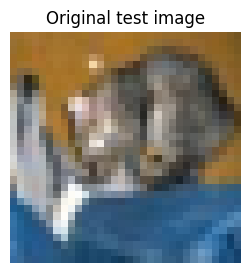

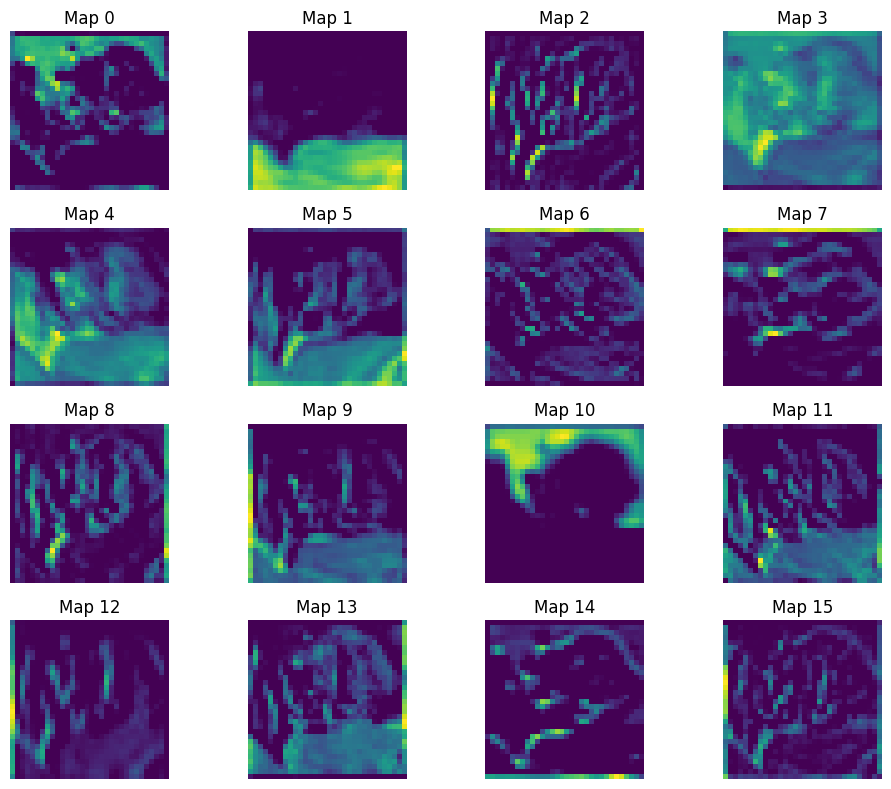

In [11]:
# Choose one test image and keep the batch dimension.
sample = x_test[0:1]

# Build a model that returns activations from the first convolution.
feature_model = tf.keras.Model(
    inputs=simple_cnn.inputs,
    outputs=simple_cnn.get_layer("simple_conv1").output
)

# Run forward propagation to obtain feature maps.
feature_maps = feature_model.predict(sample, verbose=0)
print("Feature-map tensor shape:", feature_maps.shape)

# Show the original image.
plt.figure(figsize=(3, 3))
plt.imshow(sample[0])
plt.title("Original test image")
plt.axis("off")
plt.show()

# Show the first 16 feature maps.
plt.figure(figsize=(10, 8))
for i in range(min(16, feature_maps.shape[-1])):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.title(f"Map {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Task 3: Simple CNN and Learned Filter Analysis

9. **Learned Kernel Tensor vs. Feature-Map Tensor:**
   - The kernel tensor holds static filter weights, whereas the feature map holds dynamic output activations response to an input.

**Observations:**
- First-layer kernels act as basic color, texture, and edge pattern detectors.
- Active feature maps highlight corresponding boundaries of the input object while inactive ones remain dark.

**Actual Results:**
- **Simple CNN test loss:** 0.7857
- **Simple CNN test accuracy:** 0.7290
- **First Conv2D kernel shape:** (3, 3, 3, 32)
- **First-layer feature-map shape:** (1, 32, 32, 32)

AlexNet — Theory, Diagram and Uses

Original AlexNet — simplified flow

Input image (commonly 227×227×3 in common descriptions)

↓

Conv1: 96 filters, 11×11, stride 4 → ReLU → MaxPool

↓

Conv2: 256 filters, 5×5 → ReLU → MaxPool

↓

Conv3: 384 filters, 3×3 → ReLU

↓

Conv4: 384 filters, 3×3 → ReLU

↓

Conv5: 256 filters, 3×3 → ReLU → MaxPool

↓

Flatten → Dense 4096 → Dropout → Dense 4096 → Dropout

↓

Output classes (1000 for the original ImageNet setup)

AlexNet-Style CNN for CIFAR-10

In [12]:
# AlexNet-style model adapted for 32x32 CIFAR-10 images.
# This is NOT the exact original ImageNet AlexNet architecture.
alexnet = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    # Early convolution stage: smaller 3x3 filters suit 32x32 inputs.
    tf.keras.layers.Conv2D(96, 3, strides=1, padding="same", activation="relu", name="alex_conv1"),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    # Second convolution stage.
    tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu", name="alex_conv2"),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    # Deeper convolution stages.
    tf.keras.layers.Conv2D(384, 3, padding="same", activation="relu", name="alex_conv3"),
    tf.keras.layers.Conv2D(384, 3, padding="same", activation="relu", name="alex_conv4"),
    tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu", name="alex_conv5"),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    # Convert the final feature maps to a vector.
    tf.keras.layers.Flatten(),

    # Smaller fully connected layer than original AlexNet to reduce compute.
    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    # Ten CIFAR-10 class probabilities.
    tf.keras.layers.Dense(10, activation="softmax")
])

# Use the same optimizer, loss and metric as the simple CNN.
alexnet.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Inspect AlexNet-style layer output sizes and parameter counts.
alexnet.summary()

# Train for five epochs for a fair, time-limited classroom comparison.
alex_history = alexnet.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Evaluate on the same held-out test set.
alex_loss, alex_acc = alexnet.evaluate(x_test, y_test, verbose=1)
print("AlexNet-style test loss:", alex_loss)
print("AlexNet-style test accuracy:", alex_acc)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ alex_conv1 (Conv2D)             │ (None, 32, 32, 96)     │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv2 (Conv2D)             │ (None, 16, 16, 256)    │       221,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv3 (Conv2D)             │ (None, 8, 8, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv4 (Conv2D)             │ (None, 8, 8, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv5 (Conv2D)             │ (None, 8, 8, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,424,522 (20.69 MB)

 Trainable params: 5,424,522 (20.69 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 32s 60ms/step - accuracy: 0.3857 - loss: 1.6597 - val_accuracy: 0.5228 - val_loss: 1.2907
Epoch 2/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.5699 - loss: 1.1963 - val_accuracy: 0.6260 - val_loss: 1.0206
Epoch 3/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.6576 - loss: 0.9712 - val_accuracy: 0.6638 - val_loss: 0.9398
Epoch 4/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.7154 - loss: 0.8086 - val_accuracy: 0.7104 - val_loss: 0.8172
Epoch 5/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.7608 - loss: 0.6879 - val_accuracy: 0.7272 - val_loss: 0.7709
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7355 - loss: 0.7805
AlexNet-style test loss: 0.7804627418518066
AlexNet-style test accuracy: 0.7354999780654907


### Task 4: AlexNet Theory and Implementation

10. **Roles of Layers:**
    - **Convolution:** Extracts spatial feature hierarchies through parameterized mathematical filters.
    - **ReLU:** Introduces non-linearity to allow learning of complex non-linear mappings.
    - **Pooling:** Downsamples spatial dimensions to achieve translation invariance.
    - **FC Layer:** Maps high-level abstract features to class score distributions.
    - **Dropout:** Overfitting prevention technique that randomly deactivates neurons during training.

12. **Training behavior:**
    - The model reaches ~73.55% accuracy within 5 epochs, displaying swift convergence without clear signs of early overfitting.

13. **AlexNet-style vs. Original AlexNet:**
    - It is adapted for 32x32 images with smaller 3x3 kernels and downscaled dense layers instead of the original 11x11 kernels for 227x227 inputs.

**Actual Results:**
- **AlexNet-style test loss:** 0.7805
- **AlexNet-style test accuracy:** 0.7355
- **Epochs / batch size:** 5 epochs / 128 batch size

Compare Simple CNN and AlexNet-Style Model

In [13]:
# Print a compact comparison using actual values from your run.
print("Model comparison on CIFAR-10 test set")
print("-" * 52)
print(f"Simple CNN | test loss: {simple_loss:.4f} | test accuracy: {simple_acc:.4f}")
print(f"AlexNet-style| test loss: {alex_loss:.4f} | test accuracy: {alex_acc:.4f}")

Model comparison on CIFAR-10 test set
----------------------------------------------------
Simple CNN | test loss: 0.7857 | test accuracy: 0.7290
AlexNet-style| test loss: 0.7805 | test accuracy: 0.7355


### Task 5: Compare Simple CNN and AlexNet-Style CNN

14. **Comparison Table**

| Model | Epochs | Batch Size | Test Loss | Test Accuracy |
| :--- | :---: | :---: | :---: | :---: |
| **Simple CNN** | 50 | 128 | 0.7857 | 0.7290 |
| **AlexNet-style** | 5 | 128 | 0.7805 | 0.7355 |

15. **Performance Analysis:**
    - **Better Model:** AlexNet-style CNN performed better by achieving higher accuracy (73.55% vs. 72.90%) in far fewer epochs (5 vs 50).
    - **Reasons:** (1) Deeper feature extraction pathways and higher representation parameter capacity. (2) Layer architecture combines hierarchical abstractions efficiently.

16. **Conclusion:**
    - Fixed filters provide fast predefined features, whereas learned filters adapt to training distributions; deep CNN hierarchies generate complex feature maps, though our experiment is limited by training epoch discrepancies.

Note that CNN was on 50 epochs while AlexNet CNN was only on 5 epochs. Difference is the number of features extracted.